# 01 - Multi-Timeframe BTC/USDT Data Acquisition
## Machine Learning Lab Project: Cryptocurrency Price Forecasting

### 🎯 Objective
Acquire historical OHLCV (Open, High, Low, Close, Volume) data for Bitcoin (`BTC/USDT`) across **all standard and custom trading timeframes**:
- **Scalping / Ultra Short-term:** `1m`, `3m`, `5m`, `10m`
- **Intraday:** `15m`, `30m`, `1h`, `2h`, `4h`
- **Swing & Position Trading:** `12h`, `24h` (Daily), `4d`, `30d` (Monthly)

We use the CCXT library connecting directly to the **Binance Spot Public API** without requiring private keys, followed by standard resampling for non-native intervals.

In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Add parent directory to path to import local modular package
sys.path.append(os.path.abspath('..'))
import src

print("Environment initialized successfully.")
print("Target Timeframes:", src.DEFAULT_TIMEFRAMES)

Environment initialized successfully.
Target Timeframes: ['1m', '3m', '5m', '10m', '15m', '30m', '1h', '2h', '4h', '12h', '24h', '4d', '30d']


### 📡 Fetching Historical Data & Resampling Custom Timeframes
We download high-resolution candles for native timeframes, and accurately aggregate OHLCV candles to construct custom intervals (`10m`, `4d`, `30d`).

In [2]:
# Download historical datasets and save to data/raw/
saved_files = src.fetch_all_timeframes(output_dir='../data/raw', target_candles=800)

summary_rows = []
for tf, path in saved_files.items():
    df = pd.read_csv(path)
    summary_rows.append({
        'Timeframe': tf,
        'Candle_Count': len(df),
        'Start_Time': df['timestamp'].iloc[0],
        'End_Time': df['timestamp'].iloc[-1],
        'Min_Close_$': round(df['close'].min(), 2),
        'Max_Close_$': round(df['close'].max(), 2),
        'File_Size_KB': round(os.path.getsize(path) / 1024, 1)
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

Fetching BTC/USDT [1m] ...


Fetching BTC/USDT [3m] ...


Fetching BTC/USDT [5m] ...


Fetching BTC/USDT [15m] ...


Fetching BTC/USDT [30m] ...


...

Fetching BTC/USDT [4h] ...


Fetching BTC/USDT [12h] ...


Fetching BTC/USDT [24h] ...


Resampling 10m from 5m base data...
Resampling 4d and 30d from 24h (1d) base data...
Data acquisition complete. Saved files for timeframes: ['1m', '3m', '5m', '15m', '30m', '1h', '2h', '4h', '12h', '24h', '10m', '4d', '30d']


,Timeframe,Candle_Count,Start_Time,End_Time,Min_Close_$,Max_Close_$,File_Size_KB
0,1m,800,2026-10-20 05:26:00,2026-10-20 18:45:00,81344.63,83343.97,49.5
1,3m,800,2026-10-19 02:48:00,2026-10-20 18:45:00,81272.26,83325.73,49.9
2,5m,800,2026-10-18 00:10:00,2026-10-20 18:45:00,80808.00,83276.75,50.1
3,15m,800,2026-10-12 11:00:00,2026-10-20 18:45:00,80208.89,84168.00,50.5
4,30m,800,2026-10-04 03:00:00,2026-10-20 18:30:00,80208.89,86944.67,50.7
5,1h,800,2026-09-17 11:00:00,2026-10-20 18:00:00,76415.85,87166.95,50.8
6,2h,800,2026-08-15 04:00:00,2026-10-20 18:00:00,62900.00,86704.27,51.0
7,4h,800,2026-06-09 12:00:00,2026-10-20 16:00:00,58381.99,86704.27,51.3
8,12h,800,2025-09-16 00:00:00,2026-10-20 12:00:00,58622.03,124658.54,52.2
9,24h,800,2024-08-12,2026-10-20,53962.97,124658.54,45.9


### 🔍 Data Verification & Visual Inspection
Let's inspect sample candles from the `1h` timeframe to understand the structure of the data.

In [3]:
df_1h = src.load_timeframe_data('1h', data_dir='../data/raw')
print("Shape of 1h data:", df_1h.shape)
df_1h.head()

Shape of 1h data: (800, 6)


,timestamp,open,high,low,close,volume
0,2026-09-17 11:00:00,76402.01,76488.73,76179.00,76482.00,329.95092
1,2026-09-17 12:00:00,76482.00,77179.47,76398.93,76736.59,970.25031
2,2026-09-17 13:00:00,76736.59,76889.66,76000.00,76694.07,1013.37341
3,2026-09-17 14:00:00,76694.06,77088.05,76391.44,76502.46,941.27248
4,2026-09-17 15:00:00,76502.45,76862.85,76275.00,76780.01,472.36489


### 📊 Multi-Timeframe Price Overview
Plotting Bitcoin price across three distinct granularities (`15m` short-term, `1h` medium-term, and `24h` macro-trend).

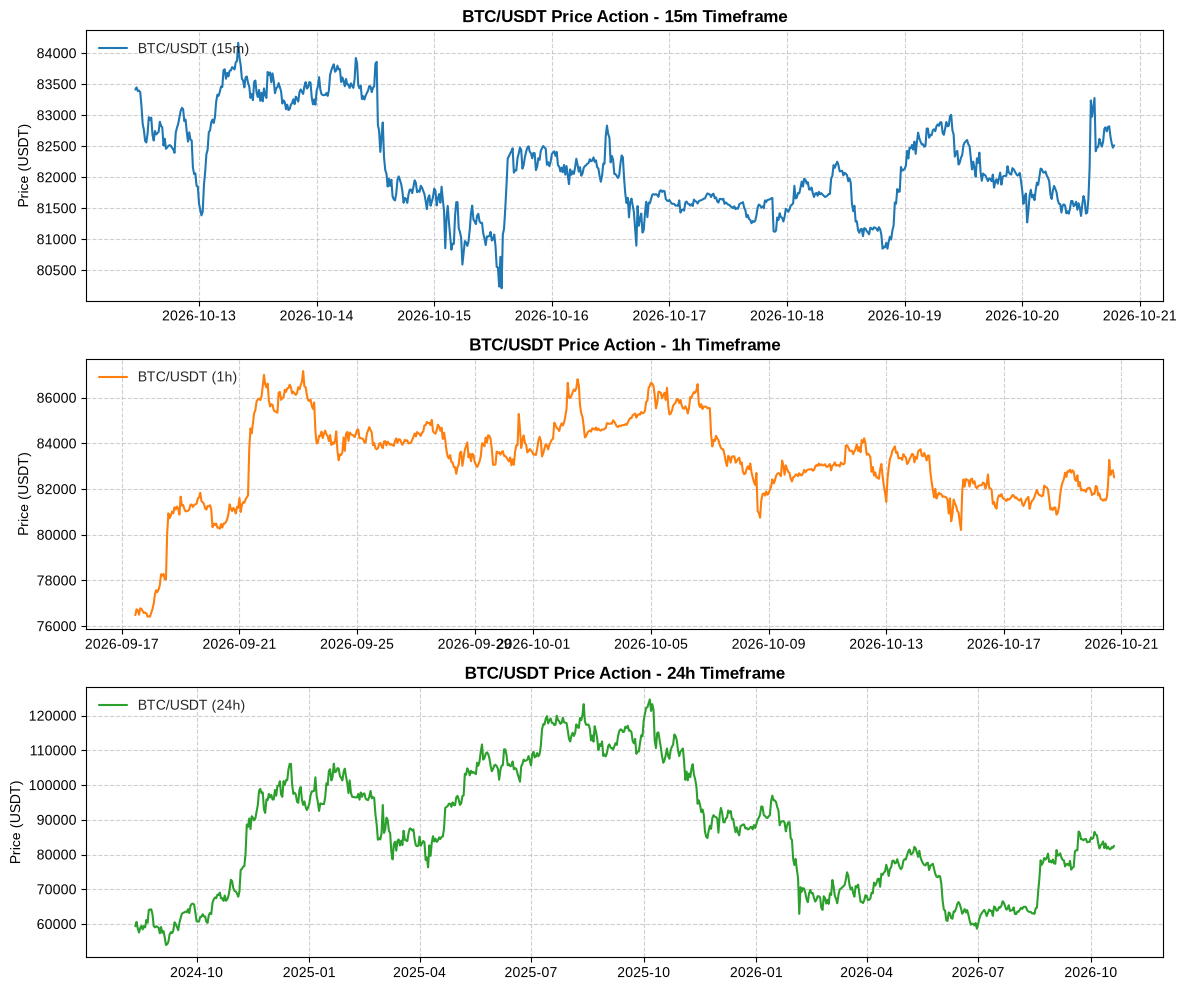

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=False)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

sample_tfs = ['15m', '1h', '24h']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for ax, tf, col in zip(axes, sample_tfs, colors):
    df_temp = src.load_timeframe_data(tf, data_dir='../data/raw')
    ax.plot(pd.to_datetime(df_temp['timestamp']), df_temp['close'], label=f'BTC/USDT ({tf})', color=col, linewidth=1.5)
    ax.set_title(f'BTC/USDT Price Action - {tf} Timeframe', fontsize=12, fontweight='bold')
    ax.set_ylabel('Price (USDT)')
    ax.legend(loc='upper left')
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### 📝 Lab Summary & Key Takeaways
1. Data was acquired across **13 distinct timeframes** spanning 1-minute high-frequency candles to 30-day macro bars.
2. Custom intervals (`10m`, `4d`, `30d`) were constructed using standard financial resampling (`open: first`, `high: max`, `low: min`, `close: last`, `volume: sum`).
3. Raw data is cleanly archived in `data/raw/` for reproducible training.